Mounted at /content/drive
Total registros en CSV: 6392
Imágenes verificadas físicamente: 6392
Pacientes únicos (ID): 3358
Valores nulos en columnas clave:
ID             0
Patient Age    0
Patient Sex    0
labels         0
filename       0
dtype: int64


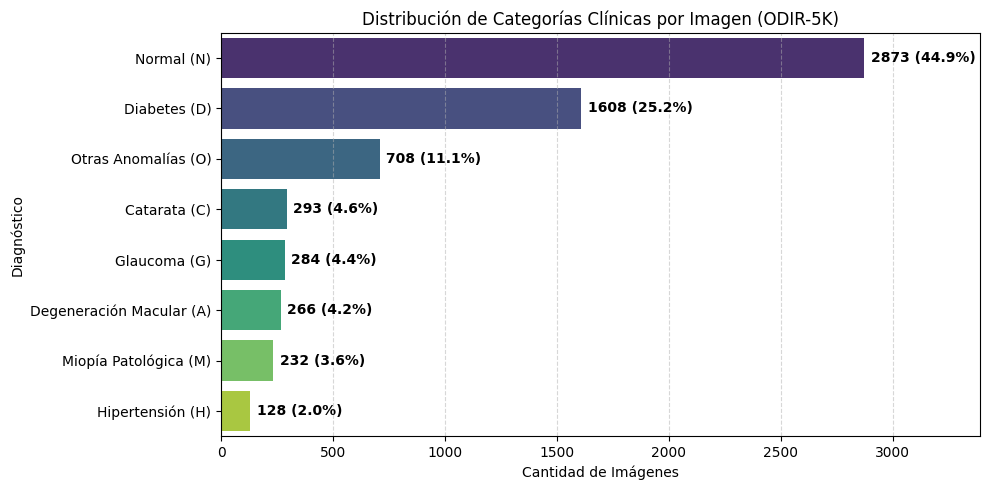

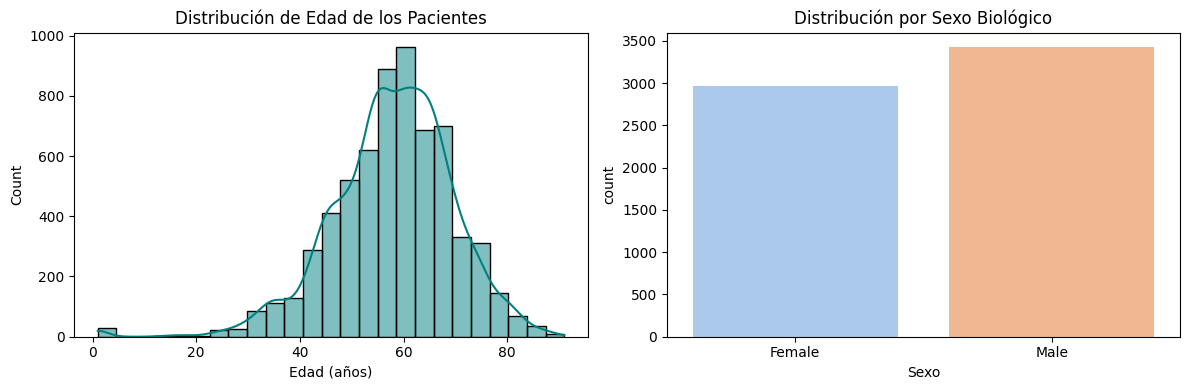

In [ ]:
# ==============================================================================
# CUADERNO 01: EXPLORACIÓN DE DATOS (EDA) E INTEGRIDAD DEL DATASET ODIR-5K
# ==============================================================================
from google.colab import drive
import os
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Montar Google Drive y definir rutas
drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/BaseDatos'
CSV_PATH = os.path.join(BASE_DIR, 'full_df.csv')
PREPROC_DIR = os.path.join(BASE_DIR, 'preprocessed_images')

assert os.path.exists(CSV_PATH), f"No se encontró el archivo {CSV_PATH}"
assert os.path.exists(PREPROC_DIR), f"No se encontró la carpeta {PREPROC_DIR}"

# 2. Cargar metadatos y verificar existencia física de las imágenes
df = pd.read_csv(CSV_PATH)
archivos_existentes = set(os.listdir(PREPROC_DIR))
df['existe_archivo'] = df['filename'].isin(archivos_existentes)

print(f"Total registros en CSV: {len(df)}")
print(f"Imágenes verificadas físicamente: {df['existe_archivo'].sum()}")
print(f"Pacientes únicos (ID): {df['ID'].nunique()}")
print(f"Valores nulos en columnas clave:\n{df[['ID', 'Patient Age', 'Patient Sex', 'labels', 'filename']].isnull().sum()}")

# 3. Extraer clase individual por ojo
df['clase'] = df['labels'].apply(lambda x: ast.literal_eval(x)[0])
nombres_clases = {
    'N': 'Normal (N)',
    'D': 'Diabetes (D)',
    'G': 'Glaucoma (G)',
    'C': 'Catarata (C)',
    'A': 'Degeneración Macular (A)',
    'H': 'Hipertensión (H)',
    'M': 'Miopía Patológica (M)',
    'O': 'Otras Anomalías (O)'
}
df['clase_nombre'] = df['clase'].map(nombres_clases)

# 4. Visualización 1: Desbalance de Clases
conteo_clases = df['clase_nombre'].value_counts()
plt.figure(figsize=(10, 5))
sns.barplot(x=conteo_clases.values, y=conteo_clases.index, hue=conteo_clases.index, palette='viridis', legend=False)
plt.title('Distribución de Categorías Clínicas por Imagen (ODIR-5K)')
plt.xlabel('Cantidad de Imágenes')
plt.ylabel('Diagnóstico')
for i, v in enumerate(conteo_clases.values):
    plt.text(v + 30, i, f"{v} ({v/len(df)*100:.1f}%)", va='center', fontweight='bold')
plt.xlim(0, conteo_clases.max() * 1.18)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 5. Visualización 2: Distribución Demográfica (Edad y Sexo)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Patient Age'], bins=25, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribución de Edad de los Pacientes')
axes[0].set_xlabel('Edad (años)')

sns.countplot(data=df, x='Patient Sex', hue='Patient Sex', palette='pastel', legend=False, ax=axes[1])
axes[1].set_title('Distribución por Sexo Biológico')
axes[1].set_xlabel('Sexo')
plt.tight_layout()
plt.show()